# Lab 03 – Developing a Tiny Transformer Language Model
**Module:** PUSL3205 – Large Language Models and Generative AI  
**Student Name:** HWS Sathsarani  
**Student ID:** 10967106  
**Dataset:** TinyStories (Hugging Face) | **Model:** Character-level Transformer | **Tools:** Google Colab (T4 GPU), PyTorch

Based on the class reference code and developed with AI assistance

##1. Install and Import Libraries
Installs the Hugging Face `datasets` library and imports PyTorch, math and plotting tools.

In [1]:
!pip install -q datasets

### Reproducibility and Device Setup
Fixes the random seed so results can be repeated, and selects the GPU if available.


In [2]:
from datasets import load_dataset
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# 2.Load and Explore the TinyStories Dataset
dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:20000]"
)

dataset = dataset.train_test_split(
    test_size=0.1,
    seed=42
)

train_text = "\n".join(dataset["train"]["text"])
val_text = "\n".join(dataset["test"]["text"])

print("Training stories:", len(dataset["train"]))
print("Validation stories:", len(dataset["test"]))
print("\nSample story:")
print(train_text[:500])

Device: cuda


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

... (5 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Training stories: 18000
Validation stories: 2000

Sample story:
Once upon a time, there was a bald man named Tom. Tom had a mask that he loved to wear. One day, he lost his mask and was very sad.

Tom looked for his mask everywhere. He looked under his bed and in the toy box, but he could not find it. Then, he saw the mask high up on a shelf. Tom tried to reach for it, but he was not tall enough.

Tom had an idea. He got a big chair and stood on it. Now he could reach the mask! He put on the mask and was very happy. Tom learned that sometimes, we need help t


## 3.Character-Level Tokenization
Creates a vocabulary of unique characters and converts text into numerical IDs (and back).

In [3]:
chars = sorted(set(train_text + val_text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
def encode(text):
    return [stoi[ch] for ch in text]
def decode(ids):
    return "".join(itos[int(i)] for i in ids)


train_data = torch.tensor(
    encode(train_text), dtype=torch.long
)

val_data = torch.tensor(
    encode(val_text), dtype=torch.long
)

print("Vocabulary size:", vocab_size)
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

sample = "Once upon a time"
print("\nEncoded sample:", encode(sample))
print("Decoded sample:", decode(encode(sample)))


Vocabulary size: 97
Training characters: 16119308
Validation characters: 1791596

Encoded sample: [42, 67, 56, 58, 1, 74, 69, 68, 67, 1, 54, 1, 73, 62, 66, 58]
Decoded sample: Once upon a time


##4.Prepare Input and Target Sequences
Creates random batches of 128-character sequences. Each target is the input shifted by one character (next-token prediction).

In [4]:

block_size = 128
batch_size = 64

def get_batch(split_name):
    source = train_data if split_name == "train" else val_data

    # Randomly choose starting positions
    starts = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )
    x = torch.stack([
        source[i:i + block_size] for i in starts
    ])

    # Targets shifted by one character
    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in starts
    ])

    return x.to(device), y.to(device)


# Test one batch
x, y = get_batch("train")

print("Input shape:", x.shape)
print("Target shape:", y.shape)

print("\nInput text:")
print(decode(x[0].tolist()))

print("\nTarget text:")
print(decode(y[0].tolist()))


Input shape: torch.Size([64, 128])
Target shape: torch.Size([64, 128])

Input text:
. They want to buy new toys with the money.

Sara says, "I saw the money first. It is mine. I will buy a doll and a dress and a 

Target text:
 They want to buy new toys with the money.

Sara says, "I saw the money first. It is mine. I will buy a doll and a dress and a h


##5.Build the Transformer Architecture
Defines token and positional embeddings, 4 Transformer layers with 4-head masked self-attention, feed-forward layers, residual connections and layer normalization.

In [5]:
# Model settings
embed_dim = 128
num_heads = 4
num_layers = 4
ff_dim = 512
dropout = 0.1

class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        # character IDs into vectors
        self.token_emb = nn.Embedding(vocab_size, embed_dim)

        # Represent character positions
        self.pos_emb = nn.Embedding(block_size, embed_dim)

        # Define one Transformer encoder layer
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        # Stack four Transformer layers
        self.blocks = nn.TransformerEncoder(
            layer,
            num_layers=num_layers
        )

        # Predict scores for every possible next character
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx):
        B, T = idx.shape

        # Token and positional embeddings
        positions = torch.arange(T, device=idx.device)
        x = self.token_emb(idx) + self.pos_emb(positions)

        # prevent looking at future characters
        mask = torch.triu(
            torch.ones(T, T, device=idx.device, dtype=torch.bool),
            diagonal=1
        )

        # Transformer processing
        x = self.blocks(x, mask=mask)

        # Output next-character scores
        return self.lm_head(x)


# Create a fresh model
model = TinyTransformer().to(device)

print("Device:", device)
print("Vocabulary size:", vocab_size)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

# Test the forward pass
logits = model(x)

print("Input shape:", x.shape)
print("Output logits shape:", logits.shape)

Device: cuda
Vocabulary size: 97
Number of parameters: 834401
Input shape: torch.Size([64, 128])
Output logits shape: torch.Size([64, 128, 97])


##6.Initialize the Optimizer
Configures the AdamW optimizer with a learning rate of 0.0005. Cross-entropy is used as the loss function.

In [6]:
learning_rate = 0.0005

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", learning_rate)


Optimizer: AdamW
Learning rate: 0.0005


##7.Train the Model
Trains for 20 epochs × 300 steps: predict the next character, calculate cross-entropy loss, backpropagate and update the weights. Validation loss is recorded after each epoch.

In [7]:
num_epochs = 20
steps_per_epoch = 300

train_history = []
val_history = []

@torch.no_grad()
def evaluate(split_name, num_batches=10):
    model.eval()
    losses = []

    for _ in range(num_batches):
        x_batch, y_batch = get_batch(split_name)
        logits = model(x_batch)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y_batch.reshape(-1)
        )
        losses.append(loss.item())

    model.train()
    return sum(losses) / len(losses)


for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0

    for step in range(steps_per_epoch):
        x_batch, y_batch = get_batch("train")

        logits = model(x_batch)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y_batch.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / steps_per_epoch
    val_loss = evaluate("val", num_batches=10)

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_loss:.3f} | "
        f"Validation loss: {val_loss:.3f}"
    )

print("Training complete!")

Epoch 01 | Train loss: 2.442 | Validation loss: 2.129
Epoch 02 | Train loss: 1.933 | Validation loss: 1.659
Epoch 03 | Train loss: 1.640 | Validation loss: 1.457
Epoch 04 | Train loss: 1.494 | Validation loss: 1.360
Epoch 05 | Train loss: 1.402 | Validation loss: 1.265
Epoch 06 | Train loss: 1.337 | Validation loss: 1.210
Epoch 07 | Train loss: 1.291 | Validation loss: 1.169
Epoch 08 | Train loss: 1.256 | Validation loss: 1.143
Epoch 09 | Train loss: 1.224 | Validation loss: 1.109
Epoch 10 | Train loss: 1.202 | Validation loss: 1.089
Epoch 11 | Train loss: 1.181 | Validation loss: 1.075
Epoch 12 | Train loss: 1.164 | Validation loss: 1.059
Epoch 13 | Train loss: 1.148 | Validation loss: 1.049
Epoch 14 | Train loss: 1.138 | Validation loss: 1.031
Epoch 15 | Train loss: 1.124 | Validation loss: 1.021
Epoch 16 | Train loss: 1.114 | Validation loss: 1.014
Epoch 17 | Train loss: 1.105 | Validation loss: 1.019
Epoch 18 | Train loss: 1.094 | Validation loss: 1.009
Epoch 19 | Train loss: 1.087

##8.Monitor Training,Learning Curves
Plots training and validation loss across epochs to check learning progress and overfitting.

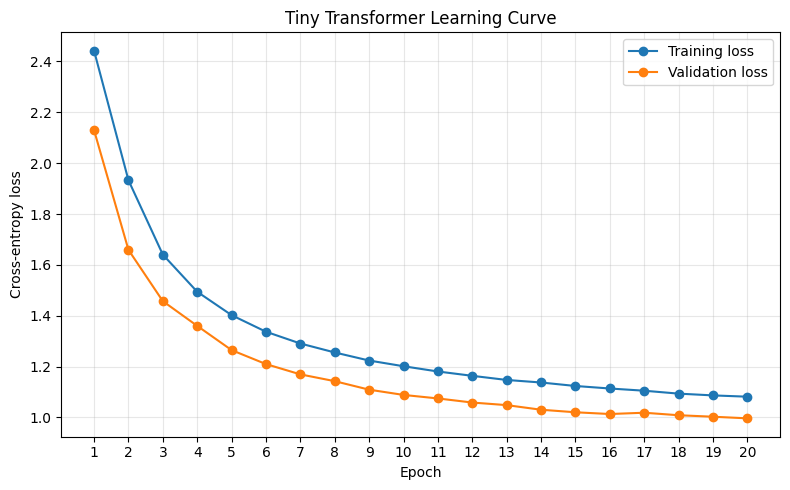

In [8]:

# Step 7: Plot the learning curves

import matplotlib.pyplot as plt

epochs = range(1, len(train_history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_history, marker="o", label="Training loss")
plt.plot(epochs, val_history, marker="o", label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer Learning Curve")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


##9.Evaluate the Model: Validation Loss and Perplexity
Perplexity = e^(loss). Lower perplexity means the model is less "surprised" by unseen text.

In [9]:
val_loss = evaluate("val", num_batches=20)
val_perplexity = math.exp(min(val_loss, 20))

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation perplexity: {val_perplexity:.2f}")


Validation loss: 0.9860
Validation perplexity: 2.68


##10.Generate Stories
Generates text from a starting prompt such as "Once upon a time", one character at a time. Temperature controls randomness.

In [10]:
@torch.no_grad()
def generate(prompt, max_new_chars=200, temperature=0.8):
    model.eval()

    ids = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_chars):
        # Keep only the most recent context characters
        context_input = ids[:, -block_size:]

        # Our TinyTransformer returns logits only
        logits = model(context_input)

        # Get predictions for the final character
        logits = logits[:, -1, :] / temperature

        # Convert scores into probabilities
        probs = F.softmax(logits, dim=-1)

        # Sample the next character
        next_id = torch.multinomial(probs, num_samples=1)

        # Append the predicted character
        ids = torch.cat([ids, next_id], dim=1)

    model.train()
    return decode(ids[0].tolist())
print(generate("Once upon a time"))


Once upon a time, there was a little girl named Jack. She loved to play in the garden with her fruit. One day, the little girl was happy and her friends and said, "Mia, Tom, Tom better. Anna. Can I play with you are 


In [11]:
!pip install -q -U gradio

In [12]:
import gradio as gr
def chat_with_transformer(message, history):
    if not message or not message.strip():
        return "Please enter a prompt."

    supported = "".join(ch for ch in message if ch in stoi)

    if not supported:
        return "Please enter text using supported characters."

    return generate(
        supported,
        max_new_chars=200,
        temperature=0.8
    )

demo = gr.ChatInterface(
    fn=chat_with_transformer,
    title="My Tiny Transformer",
    description="Enter a story prompt and let your model continue it.",
    examples=[
        "Once upon a time",
        "A little girl went into the forest",
        "One sunny morning"
    ]
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7463c256172df23474.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


##11.Experiment with Model Settings
### 11.1 Helper Functions
A configurable Transformer plus functions to train, evaluate and generate text from any model version.

In [13]:
# Step 10: Experiment with model settings

import time
import pandas as pd

# A version of the model whose size can be changed
class ExperimentTransformer(nn.Module):
    def __init__(self, embed_dim, num_heads, num_layers, ff_dim):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, embed_dim)
        self.pos_emb = nn.Embedding(block_size, embed_dim)

        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=ff_dim,
            dropout=0.1, batch_first=True, activation="gelu"
        )
        self.blocks = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx):
        B, T = idx.shape
        positions = torch.arange(T, device=idx.device)
        x = self.token_emb(idx) + self.pos_emb(positions)
        mask = torch.triu(torch.ones(T, T, device=idx.device, dtype=torch.bool), diagonal=1)
        x = self.blocks(x, mask=mask)
        return self.lm_head(x)


# Average loss of any model on a split
@torch.no_grad()
def evaluate_model(m, split_name, num_batches=10):
    m.eval()
    losses = []
    for _ in range(num_batches):
        xb, yb = get_batch(split_name)
        loss = F.cross_entropy(m(xb).reshape(-1, vocab_size), yb.reshape(-1))
        losses.append(loss.item())
    m.train()
    return sum(losses) / len(losses)


# Train any model and record its losses
def train_model(m, epochs, steps=200):
    opt = torch.optim.AdamW(m.parameters(), lr=0.0005)
    train_hist, val_hist = [], []
    for epoch in range(epochs):
        m.train()
        total = 0.0
        for _ in range(steps):
            xb, yb = get_batch("train")
            loss = F.cross_entropy(m(xb).reshape(-1, vocab_size), yb.reshape(-1))
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item()
        train_hist.append(total / steps)
        val_hist.append(evaluate_model(m, "val"))
    return train_hist, val_hist


# Generate text from any model
@torch.no_grad()
def generate_from(m, prompt, max_new_chars=120, temperature=0.8):
    m.eval()
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    for _ in range(max_new_chars):
        logits = m(ids[:, -block_size:])[:, -1, :] / temperature
        next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)
    m.train()
    return decode(ids[0].tolist())

### 11.2 Run the Experiments
Compares four settings: small vs large model, 4 heads vs 1 head, and 10 vs 3 epochs.

In [14]:
experiments = [
    {"name": "A: Small (2 layers, 2 heads, 64-dim)",  "embed_dim": 64,  "num_heads": 2, "num_layers": 2, "ff_dim": 128, "epochs": 10},
    {"name": "B: Large (4 layers, 4 heads, 128-dim)", "embed_dim": 128, "num_heads": 4, "num_layers": 4, "ff_dim": 512, "epochs": 10},
    {"name": "C: Large, 1 head only",                 "embed_dim": 128, "num_heads": 1, "num_layers": 4, "ff_dim": 512, "epochs": 10},
    {"name": "D: Large, only 3 epochs",               "embed_dim": 128, "num_heads": 4, "num_layers": 4, "ff_dim": 512, "epochs": 3},
]

results = []
histories = {}

for exp in experiments:
    torch.manual_seed(42)
    m = ExperimentTransformer(exp["embed_dim"], exp["num_heads"], exp["num_layers"], exp["ff_dim"]).to(device)

    start = time.time()
    train_hist, val_hist = train_model(m, epochs=exp["epochs"])
    duration = time.time() - start

    final_val = evaluate_model(m, "val", num_batches=20)
    histories[exp["name"]] = val_hist

    results.append({
        "Experiment": exp["name"],
        "Parameters": sum(p.numel() for p in m.parameters()),
        "Val loss": round(final_val, 3),
        "Perplexity": round(math.exp(min(final_val, 20)), 2),
        "Time (s)": round(duration, 1),
        "Sample": generate_from(m, "Once upon a time")
    })
    print("Finished:", exp["name"])

results_df = pd.DataFrame(results)
results_df

Finished: A: Small (2 layers, 2 heads, 64-dim)
Finished: B: Large (4 layers, 4 heads, 128-dim)


/tmp/ipykernel_638/790656894.py:17: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.blocks = nn.TransformerEncoder(layer, num_layers=num_layers)


Finished: C: Large, 1 head only
Finished: D: Large, only 3 epochs


,Experiment,Parameters,Val loss,Perplexity,Time (s),Sample
0,"A: Small (2 layers, 2 heads, 64-dim)",87649,1.712,5.54,26.4,"Once upon a time a said, Lery, saw anted the c..."
1,"B: Large (4 layers, 4 heads, 128-dim)",834401,1.188,3.28,70.2,"Once upon a time, there was a little belong na..."
2,"C: Large, 1 head only",834401,1.186,3.27,63.4,"Once upon a time, there was a little girl name..."
3,"D: Large, only 3 epochs",834401,1.638,5.14,20.6,"Once upon a time, ske, bag be it a toir put it..."


### 11.3 Compare Validation Loss Curves

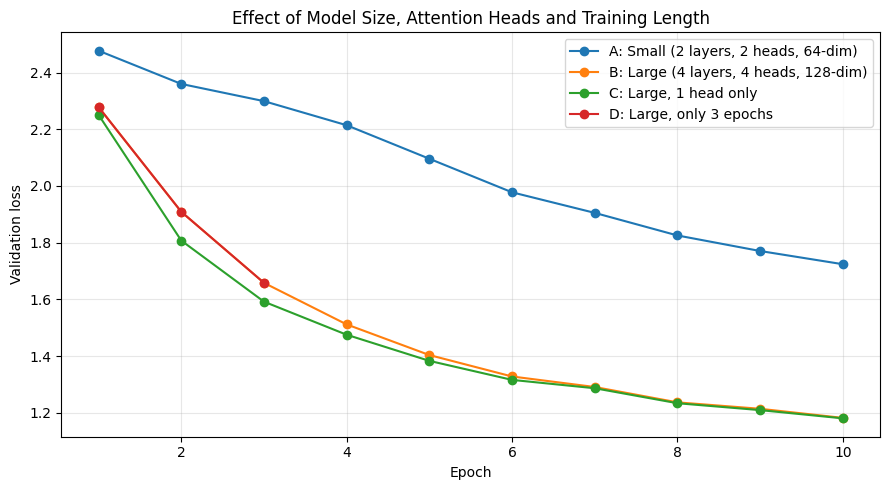

In [15]:
plt.figure(figsize=(9, 5))
for name, hist in histories.items():
    plt.plot(range(1, len(hist) + 1), hist, marker="o", label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Effect of Model Size, Attention Heads and Training Length")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 11.4 Compare Generated Text

In [16]:
for r in results:
    print(f"--- {r['Experiment']} ---")
    print(r["Sample"])
    print()

--- A: Small (2 layers, 2 heads, 64-dim) ---
Once upon a time a said, Lery, saw anted the core. The woulde gure wer of a co ther dider the wanto to that walk fand and the barad to t

--- B: Large (4 layers, 4 heads, 128-dim) ---
Once upon a time, there was a little belong named Lily. She loved to play with old and walked to playing with the cato take a park of th

--- C: Large, 1 head only ---
Once upon a time, there was a little girl named Mom. It knew liked to play with the big with there bean and spactick going in the wood. 

--- D: Large, only 3 epochs ---
Once upon a time, ske, bag be it a toir put it jo his. Jom she was a he said a ang he gack stark happ and to he pust surowe and to and t



##12.Save the Trained Model
Saves the model weights, optimizer state, vocabulary and configuration so the model can be reloaded later.

In [17]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "vocab_size": vocab_size,
    "block_size": block_size,
    "stoi": stoi,
    "itos": itos,
    "config": {
        "embed_dim": embed_dim,
        "num_heads": num_heads,
        "num_layers": num_layers,
        "ff_dim": ff_dim,
        "dropout": dropout
    }
}

torch.save(checkpoint, "tiny_transformer_checkpoint.pth")

print("Model checkpoint saved successfully!")

Model checkpoint saved successfully!


## Discussion – Mechanisms Used to Improve Performance
- **Multi-head self-attention:** lets each character focus on the important earlier characters.
- **Causal mask:** stops the model from seeing future characters, so it truly learns next-character prediction.
- **Positional embeddings:** tell the model the order of the characters.
- **Residual connections and layer normalization:** keep training stable in deeper models.
- **Dropout (0.1):** reduces overfitting in the larger model.
- **AdamW optimizer:** gives faster and more stable training.

## Observations and Conclusion
- My final model (4 layers, 4 heads, 128-dim, 834,401 parameters) reached a **validation loss of 0.986** and a **perplexity of 2.68**, meaning it chooses between fewer than 3 likely characters out of 97.
- Training and validation loss decreased steadily and stayed close together, so the model was **not overfitting**.

| Experiment | Val loss | Perplexity | Time (s) |
|---|---|---|---|
| A: Small (2 layers, 2 heads, 64-dim) | 1.712 | 5.54 | 29.0 |
| B: Large (4 layers, 4 heads, 128-dim) | 1.188 | 3.28 | 69.1 |
| C: Large, 1 head only | 1.186 | 3.27 | 60.2 |
| D: Large, only 3 epochs | 1.638 | 5.14 | 19.6 |

- **A bigger model** and **longer training** gave the biggest improvements: the text changed from broken words to real sentences.
- **1 head performed the same as 4 heads**, so the number of heads made little difference at this small scale.
- The model **cannot answer questions**. It only continues stories, because it was trained only on next-character prediction, not instructions (explored in Lab 04).
- **Challenges:** I fixed a size mismatch between the embedding and model sizes, and the Gradio cell blocking later cells.
- **Limitations:** it still makes spelling mistakes and loses meaning in longer text, because it's a small character-level model.

**Conclusion:** This lab helped me understand how a GPT-style model works, from tokenization and attention to training and text generation.